# Concentração de receita nos sellers (Olist)
**Pergunta:**  Qual é o grau de dependência da receita total em relação aos top sellers e de que forma a distribuição de faturamento entre os vendedores impacta a resiliência e os riscos do ecossistema?


## 1. Bibliotecas e arquivos

In [1]:
%matplotlib inline
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ---- Paleta de cores padrão do trabalho (identidade FIAP) ----
from cycler import cycler
ROSA = "#FE0058"           # cor principal / destaque
ROSA_ESCURO = "#A3003A"
ROSA_CLARO = "#FF8AB0"
GRAFITE = "#222222"        # cor secundária
CINZA = "#8C8C8C"
PALETA = [ROSA, GRAFITE, CINZA, ROSA_ESCURO, ROSA_CLARO]
plt.rcParams["axes.prop_cycle"] = cycler(color=PALETA)

# Procura os arquivos na pasta do Colab (funciona mesmo se o nome terminar com _1)
arq_itens   = glob.glob("/content/integrada_items_products_sellers*.csv")[0]
arq_pedidos = glob.glob("/content/integrada_orders_customers*.csv")[0]
arq_avaliacoes = glob.glob("/content/olist_order_reviews_tratado*.csv")[0]

itens   = pd.read_csv(arq_itens)
pedidos = pd.read_csv(arq_pedidos, parse_dates=["data_compra_pedido"])
avaliacoes = pd.read_csv(arq_avaliacoes)
print("Itens:", len(itens), "| Pedidos:", len(pedidos))

Itens: 112650 | Pedidos: 59742


## 2. Preparar os dados
- Juntei itens com pedidos pelo id do pedido
- **Receita = soma do preço dos produtos** (sem frete).
- Removi pedidos cancelados e indisponíveis.

In [2]:
df = itens.merge(pedidos[["id_pedido", "status_pedido", "data_compra_pedido"]], on="id_pedido")
df = df[~df["status_pedido"].isin(["canceled", "unavailable"])]

print("Receita total: R$", round(df["preco"].sum()))
print("Número de sellers:", df["id_vendedor"].nunique())

Receita total: R$ 8131610
Número de sellers: 2763


## 3. Ranking dos sellers
Soma a receita de cada seller e ordena do maior para o menor. Depois calcula a **% de cada um** e a **% acumulada**.

In [3]:
ranking = df.groupby("id_vendedor")["preco"].sum().sort_values(ascending=False).to_frame("receita")

ranking["pct"] = ranking["receita"] / ranking["receita"].sum()   # % de cada seller
ranking["pct_acum"] = ranking["pct"].cumsum()                    # % acumulada
ranking["posicao"] = range(1, len(ranking) + 1)                  # 1 = maior seller

n = len(ranking)
print("Maior seller:", round(ranking["pct"].iloc[0] * 100, 1), "% da receita")
print("Top 10:", round(ranking["pct"].head(10).sum() * 100, 1), "% da receita")
print("Top 30:", round(ranking["pct"].head(30).sum() * 100, 1), "% da receita")

Maior seller: 1.7 % da receita
Top 10: 13.1 % da receita
Top 30: 25.8 % da receita


## 4. Curva de Pareto (regra 80/20)
Mostra quantos sellers são necessários para chegar a 80% da receita.

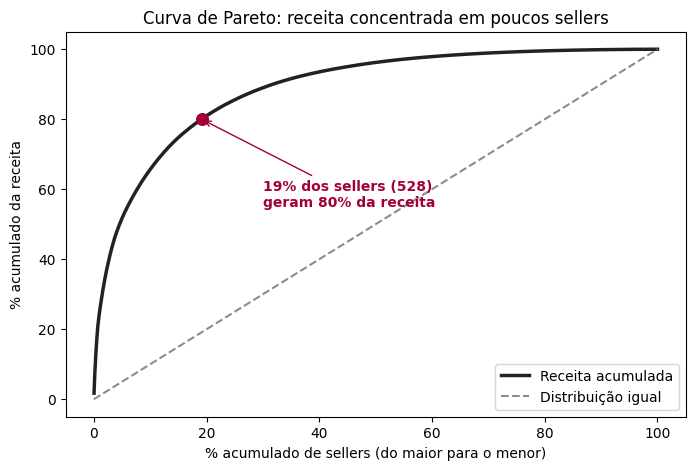

In [4]:
n_80 = (ranking["pct_acum"] < 0.80).sum() + 1      # quantos sellers até 80%
pct_sellers_80 = n_80 / n

plt.figure(figsize=(8, 5))
plt.plot(ranking["posicao"] / n * 100, ranking["pct_acum"] * 100, color=GRAFITE, linewidth=2.5, label="Receita acumulada")
plt.plot([0, 100], [0, 100], color=CINZA, linestyle="--", label="Distribuição igual")
plt.scatter([pct_sellers_80 * 100], [80], color=ROSA_ESCURO, s=70, zorder=5)
plt.annotate(f"{pct_sellers_80:.0%} dos sellers ({n_80})\ngeram 80% da receita",
             (pct_sellers_80 * 100, 80), xytext=(30, 55), color=ROSA_ESCURO, fontweight="bold",
             arrowprops=dict(arrowstyle="->", color=ROSA_ESCURO))
plt.xlabel("% acumulado de sellers (do maior para o menor)")
plt.ylabel("% acumulado da receita")
plt.title("Curva de Pareto: receita concentrada em poucos sellers")
plt.legend(loc="lower right")
plt.show()

## 5. Índices de concentração: Gini e HHI
- **Gini** (0 a 1): desigualdade entre todos os sellers. Perto de 1 = muito desigual.
- **HHI** (0 a 10.000): dependência de sellers *individuais*. Abaixo de 1.500 = sem dependência de um único seller.
- **Nº efetivo de sellers**: quantos sellers de tamanho igual dariam a mesma concentração.

In [5]:
# Gini: ordena do menor para o maior e aplica a fórmula
x = np.sort(ranking["receita"].values)
i = np.arange(1, n + 1)
gini = (2 * np.sum(i * x)) / (n * x.sum()) - (n + 1) / n

# HHI: soma dos quadrados das participações (x 10.000)
hhi = (ranking["pct"] ** 2).sum() * 10000

# Número efetivo de sellers
n_efetivo = 1 / (ranking["pct"] ** 2).sum()

print("Gini:", round(gini, 2))
print("HHI:", round(hhi))
print("Número efetivo de sellers:", round(n_efetivo))

Gini: 0.78
HHI: 36
Número efetivo de sellers: 278


## 6. Faixas de faturamento
Divide os sellers em 5 grupos e compara **% dos sellers** com **% da receita**.

              sellers    receita  % dos sellers  % da receita
faixa                                                        
Top 1%             28  2029641.1            1.0          25.0
Próx. 4%          110  2172254.2            4.0          26.7
Próx. 15%         415  2385003.5           15.0          29.3
Próx. 30%         829  1238035.6           30.0          15.2
50% inferior     1381   306675.8           50.0           3.8


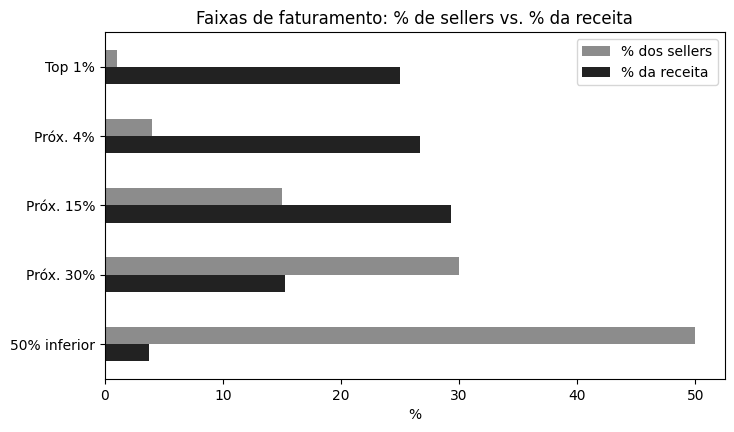

In [6]:
# Limites das faixas (em posição do ranking): 1%, 5%, 20%, 50% e 100% dos sellers
limites = [0, round(n * 0.01), round(n * 0.05), round(n * 0.20), round(n * 0.50), n]
nomes = ["Top 1%", "Próx. 4%", "Próx. 15%", "Próx. 30%", "50% inferior"]
ranking["faixa"] = pd.cut(ranking["posicao"], bins=limites, labels=nomes)

faixas = ranking.groupby("faixa", observed=True).agg(sellers=("receita", "size"), receita=("receita", "sum"))
faixas["% dos sellers"] = faixas["sellers"] / n * 100
faixas["% da receita"] = faixas["receita"] / faixas["receita"].sum() * 100
print(faixas.round(1))

faixas[["% dos sellers", "% da receita"]].plot(kind="barh", figsize=(8, 4.5), color=[CINZA, GRAFITE])
plt.gca().invert_yaxis()
plt.xlabel("%"); plt.ylabel("")
plt.title("Faixas de faturamento: % de sellers vs. % da receita")
plt.show()

## 7. Cenário de saída (stress test)
Quanto da receita se perde se os maiores sellers saírem da plataforma?

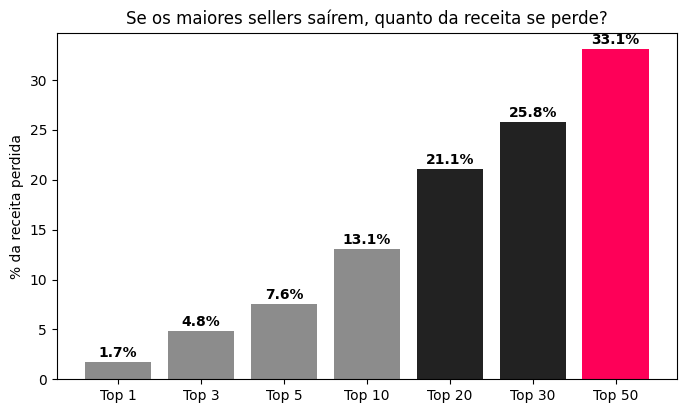

In [7]:
saidas = [1, 3, 5, 10, 20, 30, 50]
perdas = [ranking["pct"].head(k).sum() * 100 for k in saidas]

cores = [CINZA if p < 20 else GRAFITE if p < 30 else ROSA for p in perdas]
plt.figure(figsize=(8, 4.5))
barras = plt.bar([f"Top {k}" for k in saidas], perdas, color=cores)
for barra, p in zip(barras, perdas):
    plt.text(barra.get_x() + barra.get_width() / 2, p + 0.5, f"{p:.1f}%", ha="center", fontweight="bold")
plt.ylabel("% da receita perdida")
plt.title("Se os maiores sellers saírem, quanto da receita se perde?")
plt.show()

## 8. A concentração está mudando ao longo do tempo?
Para cada mês (jan/2017 a ago/2018), calcula quanto os 10 maiores sellers daquele mês representam.

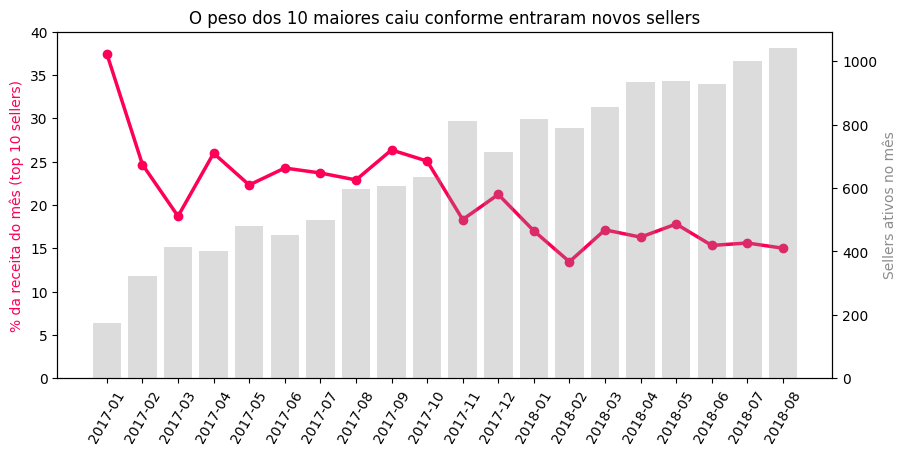

In [8]:
# Só meses completos
mensal = df[(df["data_compra_pedido"] >= "2017-01-01") & (df["data_compra_pedido"] < "2018-09-01")].copy()
mensal["mes"] = mensal["data_compra_pedido"].dt.strftime("%Y-%m")

meses, top10, sellers_ativos = [], [], []
for mes, grupo in mensal.groupby("mes"):
    receita_seller = grupo.groupby("id_vendedor")["preco"].sum().sort_values(ascending=False)
    meses.append(mes)
    top10.append(receita_seller.head(10).sum() / receita_seller.sum() * 100)
    sellers_ativos.append(len(receita_seller))

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(meses, top10, color=ROSA, marker="o", linewidth=2.5)
ax.set_ylabel("% da receita do mês (top 10 sellers)", color=ROSA)
ax.set_ylim(0, 40)
ax.tick_params(axis="x", rotation=60)
ax2 = ax.twinx()
ax2.bar(meses, sellers_ativos, color=CINZA, alpha=0.3)
ax2.set_ylabel("Sellers ativos no mês", color=CINZA)
plt.title("O peso dos 10 maiores caiu conforme entraram novos sellers")
plt.show()

## 9. Dependência por categoria
Dentro de cada categoria de produto, quanto da receita vem dos **3 maiores sellers**? Quanto maior, mais frágil a categoria.

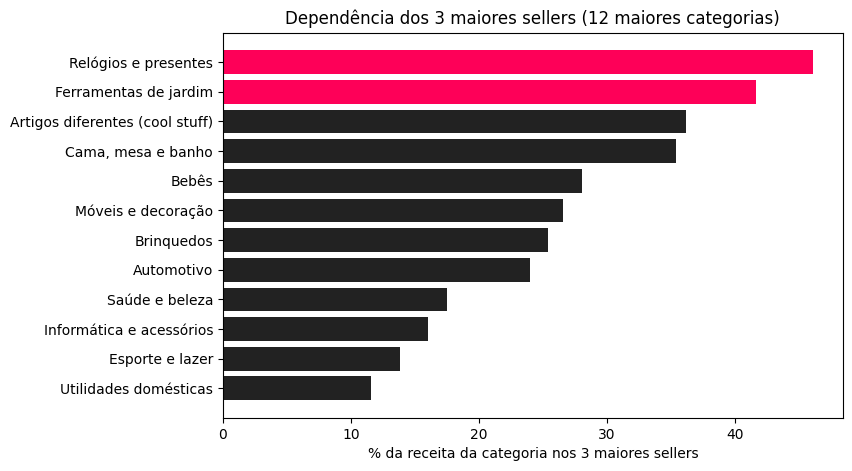

              categoria   receita  sellers  top3 (%)
55            computers  137994.0        6      90.0
20     office_furniture  159327.0       27      81.0
22        watches_gifts  725064.0       87      46.0
16           stationery  138873.0      149      46.0
34  musical_instruments  113344.0       59      45.0


In [9]:
df["categoria"] = df["nome_categoria_produto_ingles"].fillna("sem_categoria")

# Receita de cada seller dentro de cada categoria
rec_cat_seller = df.groupby(["categoria", "id_vendedor"])["preco"].sum()

linhas = []
for cat in df["categoria"].unique():
    s = rec_cat_seller[cat].sort_values(ascending=False)       # sellers dessa categoria
    linhas.append({"categoria": cat,
                   "receita": s.sum(),
                   "sellers": len(s),
                   "top3 (%)": s.head(3).sum() / s.sum() * 100})
categorias = pd.DataFrame(linhas)

# Gráfico: 12 maiores categorias por receita
grandes = categorias.sort_values("receita", ascending=False).head(12).sort_values("top3 (%)")
# Tradução dos nomes das categorias para o gráfico
traducao = {
    "watches_gifts": "Relógios e presentes",
    "garden_tools": "Ferramentas de jardim",
    "bed_bath_table": "Cama, mesa e banho",
    "cool_stuff": "Artigos diferentes (cool stuff)",
    "baby": "Bebês",
    "furniture_decor": "Móveis e decoração",
    "toys": "Brinquedos",
    "auto": "Automotivo",
    "health_beauty": "Saúde e beleza",
    "computers_accessories": "Informática e acessórios",
    "sports_leisure": "Esporte e lazer",
    "housewares": "Utilidades domésticas",
}
grandes["categoria_pt"] = grandes["categoria"].map(traducao).fillna(grandes["categoria"])

cores = [ROSA if v >= 40 else GRAFITE for v in grandes["top3 (%)"]]
plt.figure(figsize=(8, 5))
plt.barh(grandes["categoria_pt"], grandes["top3 (%)"], color=cores)
plt.xlabel("% da receita da categoria nos 3 maiores sellers")
plt.title("Dependência dos 3 maiores sellers (12 maiores categorias)")
plt.show()

# Nichos mais frágeis (categorias com receita acima de R$ 100 mil)
nichos = categorias[categorias["receita"] >= 100000].sort_values("top3 (%)", ascending=False).head(5)
print(nichos.round(0))

## 10. Os grandes sellers são também os melhores? (qualidade)
Usa a **nota de avaliação (1 a 5)** dos pedidos. Primeiro compara a nota média por faixa de faturamento; depois olha a nota dos 30 maiores sellers.

faixa
Top 1%          4.07
Próx. 4%        4.06
Próx. 15%       4.14
Próx. 30%       4.14
50% inferior    4.14
Name: nota_avaliacao, dtype: float64


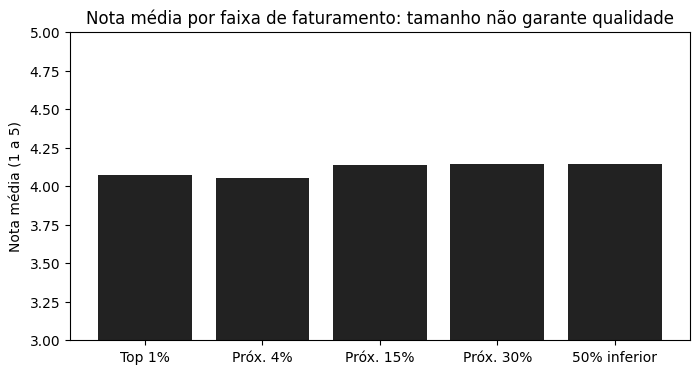

In [10]:
# Nota média de cada pedido e ligação com o seller e a faixa
notas = avaliacoes.groupby("id_pedido")["nota_avaliacao"].mean().reset_index()
qual = df[["id_pedido", "id_vendedor"]].drop_duplicates().merge(notas, on="id_pedido")
qual = qual.merge(ranking[["faixa"]], left_on="id_vendedor", right_index=True)

# Gráfico 1: nota média por faixa de faturamento
nota_faixa = qual.groupby("faixa", observed=True)["nota_avaliacao"].mean()
print(nota_faixa.round(2))
plt.figure(figsize=(8, 4))
plt.bar(nota_faixa.index.astype(str), nota_faixa.values, color=GRAFITE)
plt.ylim(3, 5)
plt.ylabel("Nota média (1 a 5)")
plt.title("Nota média por faixa de faturamento: tamanho não garante qualidade")
plt.show()

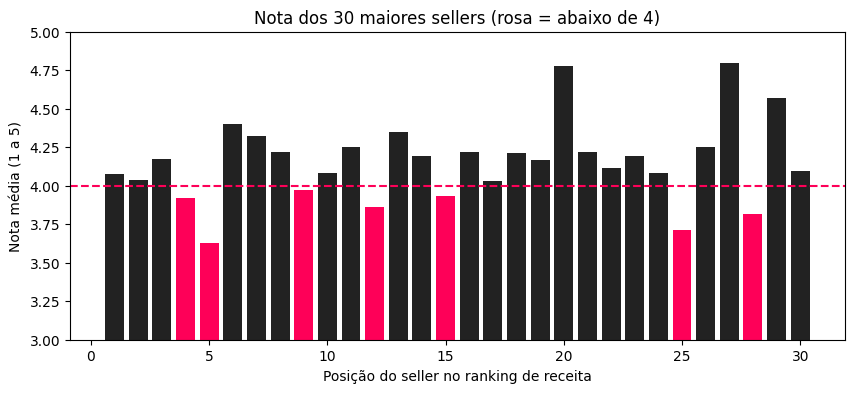

Sellers do top 30 com nota abaixo de 4: 7
Pior nota do top 30: 3.62
Receita total desses sellers: 6.4 % da receita


In [11]:
# Gráfico 2: nota dos 30 maiores sellers (rosa = nota abaixo de 4)
nota_seller = qual.groupby("id_vendedor")["nota_avaliacao"].mean()
top30 = ranking.head(30).copy()
top30["nota"] = nota_seller

cores = [ROSA if v < 4 else GRAFITE for v in top30["nota"]]
plt.figure(figsize=(10, 4))
plt.bar(top30["posicao"], top30["nota"], color=cores)
plt.axhline(4, color=ROSA, linestyle="--")
plt.ylim(3, 5)
plt.xlabel("Posição do seller no ranking de receita")
plt.ylabel("Nota média (1 a 5)")
plt.title("Nota dos 30 maiores sellers (rosa = abaixo de 4)")
plt.show()

abaixo_4 = top30[top30["nota"] < 4]
print("Sellers do top 30 com nota abaixo de 4:", len(abaixo_4))
print("Pior nota do top 30:", round(top30["nota"].min(), 2))
print("Receita total desses sellers:", round(abaixo_4["pct"].sum() * 100, 1), "% da receita")